# <span style="color:#1F4E79;">Synthetic CDM Parameter Recovery</span>

### Reproducing Figure 1(a) · Seshadri, Peysakhovich & Ugander (2019)

*Discovering Context Effects from Raw Choice Data*

Study how accurately a full Context-Dependent Model recovers known
interaction parameters as the number of observed choices increases.

**Workflow:** Generate parameters → Simulate choices → Estimate parameters
→ Measure recovery error → Compare across sample sizes.

Paper-specified settings and reproduction assumptions are documented separately.

## <span style="color:#1F4E79;">1. Setup</span>

Import the libraries and existing CDM package used throughout the experiment.

In [1]:
# Import libraries and the reusable CDM package.

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

import context_dependent_model as cdm

## <span style="color:#1F4E79;">Reusable Functions and Classes</span>

Core CDM calculations are imported from `context_dependent_model`.
Paper-specific generation and experiment routines will be added to
`cdm_paper_reproduction`.

| Function or class | Purpose |
|:---|:---|
| `cdm.CDMChoiceData` | Stores choice sets, padding masks and chosen positions. |
| `cdm.center_cdm_parameters()` | Sets diagonal entries to zero and centres off-diagonal interactions. |
| `cdm.cdm_choice_utilities()` | Sums the context contributions for each available item. |
| `cdm.cdm_choice_probabilities()` | Converts utilities into choice probabilities using softmax. |
| `cdm.average_cdm_negative_log_likelihood()` | Computes the mean negative log-probability of observed choices. |
| `cdm.generate_cdm_choice_data_on_sets()` | Samples choices from a supplied interaction matrix and supplied choice sets. |
| `cdm.FullContextDependentModel` | Represents the trainable full CDM interaction matrix. |
| `cdm.optimize_full_cdm_with_adam()` | Fits a full CDM using Adam and returns optimization diagnostics. |
| `cdm.cdm_parameter_recovery_error()` | Computes off-diagonal parameter RMSE after centring both matrices. |

**Reproduction notes**

- The existing optimizer needs support for the paper's initialization procedure.
- The existing recovery metric returns RMSE; the squared-error metric for
  Figure 1(a) will be defined explicitly.
- Centring removes a common-shift ambiguity; it does not by itself guarantee
  identifiability for every collection of choice sets.

In [2]:
# Locate the project root and create directories for reproduction outputs.

PROJECT_ROOT = next(
    (
        directory
        for directory in (Path.cwd(), *Path.cwd().parents)
        if (directory / "pyproject.toml").is_file()
        and (directory / "src").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Open this notebook inside the thesis repository."
    )

EXPERIMENT_NAME = "01_synthetic_recovery"
EXPERIMENT_PATH = Path("cdm_paper_reproduction") / EXPERIMENT_NAME

FIGURE_DIRECTORY = (
    PROJECT_ROOT / "docs/thesis/images/experiments" / EXPERIMENT_PATH
)

TABLE_DIRECTORY = (
    PROJECT_ROOT / "docs/thesis/tables/experiments" / EXPERIMENT_PATH
)

RESULT_DIRECTORY = (
    PROJECT_ROOT / "results/experiments" / EXPERIMENT_PATH
)

output_directories = {
    "Figures": FIGURE_DIRECTORY,
    "LaTeX tables": TABLE_DIRECTORY,
    "Numerical results": RESULT_DIRECTORY,
}

for directory in output_directories.values():
    directory.mkdir(parents=True, exist_ok=True)

directory_summary = pd.DataFrame(
    [
        {"Output": name, "Directory": str(directory)}
        for name, directory in output_directories.items()
    ]
)

directory_summary

,Output,Directory
0,Figures,/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...
1,LaTeX tables,/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...
2,Numerical results,/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Sha...


In [3]:
# Set consistent typography, colours and display formatting.

plt.style.use("default")

PLOT_COLOURS = {
    "estimate": "#0072B2",
    "reference": "#555555",
    "individual_run": "#A7B5C5",
    "comparison": "#D55E00",
}

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "dejavuserif",
    "font.size": 11,
    "figure.figsize": (8, 5),
    "figure.dpi": 120,
    "figure.facecolor": "white",
    "figure.constrained_layout.use": True,
    "axes.facecolor": "white",
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "axes.grid": True,
    "grid.alpha": 0.20,
    "grid.linewidth": 0.7,
    "grid.linestyle": "--",
    "lines.linewidth": 2,
    "lines.markersize": 6,
    "legend.fontsize": 10,
    "legend.frameon": False,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.08,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
})

pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 20)

print("Plot and table appearance configured.")

Plot and table appearance configured.


## <span style="color:#1F4E79;">2. Experimental Configuration</span>

The synthetic recovery experiment uses six items and ten growing datasets.

Paper-specified settings are distinguished from implementation choices.
The observation-count grid and remaining optimization details will be
verified before running the complete experiment.

In [4]:
# Define the confirmed experiment settings and our reproducibility choices.

SEED = 20260831
NUMBER_OF_ITEMS = 6
NUMBER_OF_RUNS = 10

DEVICE = torch.device("cpu")
DTYPE = torch.float64

CHOICE_SET_SIZES = tuple(range(2, NUMBER_OF_ITEMS + 1))

experiment_settings = pd.DataFrame(
    [
        {
            "Setting": "Number of items",
            "Value": NUMBER_OF_ITEMS,
            "Basis": "Paper",
        },
        {
            "Setting": "Growing datasets",
            "Value": NUMBER_OF_RUNS,
            "Basis": "Paper",
        },
        {
            "Setting": "Choice-set sizes",
            "Value": str(CHOICE_SET_SIZES),
            "Basis": "All subsets containing at least two items",
        },
        {
            "Setting": "Base random seed",
            "Value": SEED,
            "Basis": "Our reproducibility choice",
        },
        {
            "Setting": "Device",
            "Value": str(DEVICE),
            "Basis": "Our implementation choice",
        },
        {
            "Setting": "Numerical dtype",
            "Value": str(DTYPE),
            "Basis": "Our implementation choice",
        },
        {
            "Setting": "Observation-count grid",
            "Value": "Pending verification",
            "Basis": "Check Figure 1(a) and authors' implementation",
        },
    ]
)

experiment_settings

,Setting,Value,Basis
0,Number of items,6,Paper
1,Growing datasets,10,Paper
2,Choice-set sizes,"(2, 3, 4, 5, 6)",All subsets containing at least two items
3,Base random seed,20260831,Our reproducibility choice
4,Device,cpu,Our implementation choice
5,Numerical dtype,torch.float64,Our implementation choice
6,Observation-count grid,Pending verification,Check Figure 1(a) and authors' implementation


## <span style="color:#1F4E79;">3. Choice-Set Universe</span>

Enumerate every subset containing at least two of the six items.

Uniform sampling over this collection gives every individual choice set
the same probability. Choice-set sizes therefore occur in proportion
to the number of subsets of each size.

In [5]:
# Enumerate all eligible choice sets and summarise their sampling probabilities.

from itertools import combinations
from math import comb

ALL_CHOICE_SETS = tuple(
    choice_set
    for size in CHOICE_SET_SIZES
    for choice_set in combinations(range(NUMBER_OF_ITEMS), size)
)

NUMBER_OF_POSSIBLE_SETS = len(ALL_CHOICE_SETS)

choice_set_summary = pd.DataFrame(
    [
        {
            "Choice-set size": size,
            "Number of possible sets": comb(NUMBER_OF_ITEMS, size),
            "Probability of this size": (
                comb(NUMBER_OF_ITEMS, size) / NUMBER_OF_POSSIBLE_SETS
            ),
        }
        for size in CHOICE_SET_SIZES
    ]
)

assert NUMBER_OF_POSSIBLE_SETS == (
    2**NUMBER_OF_ITEMS - NUMBER_OF_ITEMS - 1
)

print(f"Total possible choice sets: {NUMBER_OF_POSSIBLE_SETS}")
print(f"First five choice sets: {ALL_CHOICE_SETS[:5]}")

choice_set_summary.style.format({
    "Number of possible sets": "{:,}",
    "Probability of this size": "{:.2%}",
})

Total possible choice sets: 57
First five choice sets: ((0, 1), (0, 2), (0, 3), (0, 4), (0, 5))


,Choice-set size,Number of possible sets,Probability of this size
0,2,15,26.32%
1,3,20,35.09%
2,4,15,26.32%
3,5,6,10.53%
4,6,1,1.75%


## <span style="color:#1F4E79;">4. True CDM Parameters</span>

Generate independent standard-normal target and context matrices, with
one row per item, and construct the interactions as $U_{\mathrm{raw}} = TC^\top$.

Set the diagonal to zero and centre the off-diagonal entries. Retain the
resulting matrix as the ground truth for synthetic generation and recovery.

In [6]:
# Generate and inspect the factors and true interaction matrix.

from IPython.display import display

from cdm_paper_reproduction.synthetic import generate_paper_cdm_parameters

PARAMETER_SEED = SEED

true_target_vectors, true_context_vectors, true_interactions = (
    generate_paper_cdm_parameters(
        number_of_items=NUMBER_OF_ITEMS,
        random_seed=PARAMETER_SEED,
        device=DEVICE,
        dtype=DTYPE,
    )
)

item_labels = [f"Item {item}" for item in range(NUMBER_OF_ITEMS)]
dimension_labels = [
    f"Dimension {dimension + 1}"
    for dimension in range(NUMBER_OF_ITEMS)
]

for title, matrix, columns in (
    ("Target vectors", true_target_vectors, dimension_labels),
    ("Context vectors", true_context_vectors, dimension_labels),
    ("True interaction matrix", true_interactions, item_labels),
):
    display(
        pd.DataFrame(
            matrix.detach().cpu().numpy(),
            index=item_labels,
            columns=columns,
        )
        .style
        .format("{:.3f}")
        .set_caption(title)
    )

,Dimension 1,Dimension 2,Dimension 3,Dimension 4,Dimension 5,Dimension 6
Item 0,0.155,-1.870,0.117,-0.757,-0.209,-0.280
Item 1,0.754,0.240,0.439,0.937,0.696,0.608
Item 2,-0.464,-0.247,-1.074,0.646,0.689,0.131
Item 3,-0.627,0.879,-0.808,-0.905,3.097,-0.143
Item 4,-1.071,-0.994,1.290,0.763,-0.714,-1.068
Item 5,0.653,-0.515,0.438,1.018,0.254,-0.605


,Dimension 1,Dimension 2,Dimension 3,Dimension 4,Dimension 5,Dimension 6
Item 0,0.059,0.386,-1.531,0.005,0.372,0.705
Item 1,-1.211,-0.407,-0.066,0.914,-0.768,-0.181
Item 2,0.325,1.113,-0.675,1.745,-0.446,0.328
Item 3,-0.664,-1.112,-0.767,0.209,-0.815,0.744
Item 4,1.829,-0.137,-0.172,-2.634,-0.355,1.541
Item 5,-0.890,-0.037,-1.004,0.566,0.702,-0.779


,Item 0,Item 1,Item 2,Item 3,Item 4,Item 5
Item 0,-0.000,0.048,-3.468,1.653,2.119,-0.580
Item 1,0.120,-0.000,1.703,-1.061,-0.544,-0.614
Item 2,1.834,0.734,0.000,1.040,-2.413,2.211
Item 3,2.549,-2.763,-1.724,-0.000,-0.102,3.074
Item 4,-3.474,3.019,-1.063,0.737,-0.000,0.419
Item 5,-1.194,0.198,0.772,-0.677,-2.553,0.000


In [7]:
# Verify the shape, numerical values and centring of the true interaction matrix.

off_diagonal_mask = ~torch.eye(
    NUMBER_OF_ITEMS,
    dtype=torch.bool,
    device=true_interactions.device,
)

off_diagonal_values = true_interactions[off_diagonal_mask]

assert true_interactions.shape == (
    NUMBER_OF_ITEMS,
    NUMBER_OF_ITEMS,
)

assert torch.isfinite(true_interactions).all().item()

assert torch.allclose(
    true_interactions.diagonal(),
    torch.zeros(
        NUMBER_OF_ITEMS,
        dtype=true_interactions.dtype,
        device=true_interactions.device,
    ),
    atol=1e-10,
    rtol=0.0,
)

assert abs(off_diagonal_values.mean().item()) < 1e-10

interaction_matrix_summary = pd.DataFrame(
    {
        "Quantity": [
            "Number of items",
            "Factor dimension",
            "Interaction matrix shape",
            "Off-diagonal entries",
            "Mean off-diagonal interaction",
            "Minimum off-diagonal interaction",
            "Maximum off-diagonal interaction",
        ],
        "Value": [
            NUMBER_OF_ITEMS,
            true_target_vectors.shape[1],
            str(tuple(true_interactions.shape)),
            off_diagonal_values.numel(),
            f"{off_diagonal_values.mean().item():.6f}",
            f"{off_diagonal_values.min().item():.4f}",
            f"{off_diagonal_values.max().item():.4f}",
        ],
    }
)

display(interaction_matrix_summary)

,Quantity,Value
0,Number of items,6
1,Factor dimension,6
2,Interaction matrix shape,"(6, 6)"
3,Off-diagonal entries,30
4,Mean off-diagonal interaction,0.000000
5,Minimum off-diagonal interaction,-3.4740
6,Maximum off-diagonal interaction,3.0736


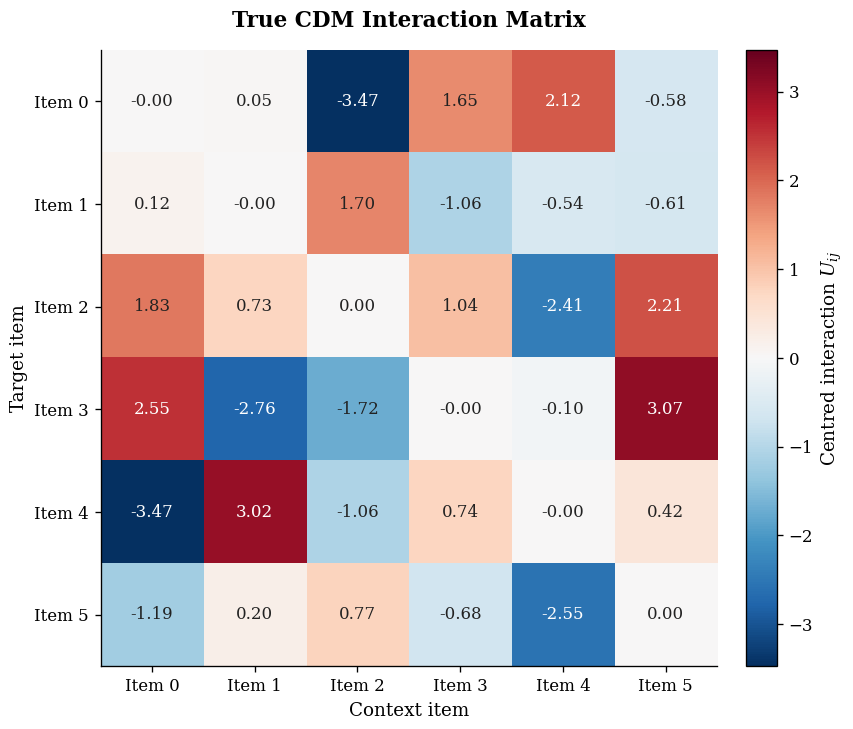

In [8]:
# Plot and save the true CDM interaction matrix with a colour scale centred at zero.

interaction_values = (
    true_interactions.detach().cpu().numpy()
)

colour_limit = float(
    np.abs(interaction_values).max()
)

if colour_limit == 0.0:
    colour_limit = 1.0

figure, axis = plt.subplots(
    figsize=(7.2, 6.0),
)

heatmap = axis.imshow(
    interaction_values,
    cmap="RdBu_r",
    vmin=-colour_limit,
    vmax=colour_limit,
    interpolation="nearest",
    aspect="equal",
)

axis.set_xticks(
    range(NUMBER_OF_ITEMS),
    labels=item_labels,
)

axis.set_yticks(
    range(NUMBER_OF_ITEMS),
    labels=item_labels,
)

axis.set_xlabel("Context item")
axis.set_ylabel("Target item")
axis.set_title(
    "True CDM Interaction Matrix",
    pad=14,
)

axis.grid(False)

for row in range(NUMBER_OF_ITEMS):
    for column in range(NUMBER_OF_ITEMS):
        value = interaction_values[row, column]

        axis.text(
            column,
            row,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=10,
            color=(
                "white"
                if abs(value) > 0.60 * colour_limit
                else "#222222"
            ),
        )

colourbar = figure.colorbar(
    heatmap,
    ax=axis,
    fraction=0.046,
    pad=0.04,
)

colourbar.set_label(
    r"Centred interaction $U_{ij}$"
)

figure.savefig(
    FIGURE_DIRECTORY / "01_true_interaction_matrix.pdf",
    bbox_inches="tight",
)

plt.show()

In [14]:
# Sample uniformly from all choice sets containing at least two items.

from itertools import combinations


def sample_uniform_subset_choice_sets(
    number_of_items: int,
    number_of_observations: int,
    *,
    random_seed: int,
    device: str | torch.device = "cpu",
) -> tuple[torch.Tensor, torch.Tensor]:
    """Return padded choice sets and a mask marking valid items."""

    if number_of_items < 2:
        raise ValueError("number_of_items must be at least 2.")

    if number_of_observations < 1:
        raise ValueError("number_of_observations must be positive.")

    possible_choice_sets = tuple(
        choice_set
        for size in range(2, number_of_items + 1)
        for choice_set in combinations(
            range(number_of_items),
            size,
        )
    )

    generator = torch.Generator(device="cpu")
    generator.manual_seed(random_seed)

    sampled_set_indices = torch.randint(
        high=len(possible_choice_sets),
        size=(number_of_observations,),
        generator=generator,
    )

    choice_sets = torch.full(
        (number_of_observations, number_of_items),
        fill_value=-1,
        dtype=torch.long,
    )

    for row, set_index in enumerate(sampled_set_indices.tolist()):
        current_choice_set = possible_choice_sets[set_index]

        choice_sets[row, :len(current_choice_set)] = torch.tensor(
            current_choice_set,
            dtype=torch.long,
        )

    choice_mask = choice_sets.ge(0)

    return (
        choice_sets.to(device),
        choice_mask.to(device),
    )

In [17]:
# Generate synthetic CDM choices on uniformly sampled subsets and inspect them.

from cdm_paper_reproduction.synthetic import (
    sample_uniform_subset_choice_sets,
)
from context_dependent_model.simulation import (
    generate_cdm_choice_data_on_sets,
)

NUMBER_OF_OBSERVATIONS = 1_000
CHOICE_SET_SEED = SEED + 1
CHOICE_OUTCOME_SEED = SEED + 2

sampled_choice_sets, sampled_choice_mask = (
    sample_uniform_subset_choice_sets(
        number_of_items=NUMBER_OF_ITEMS,
        number_of_observations=NUMBER_OF_OBSERVATIONS,
        random_seed=CHOICE_SET_SEED,
        device=DEVICE,
    )
)

synthetic_data = generate_cdm_choice_data_on_sets(
    interaction_matrix=true_interactions,
    choice_sets=sampled_choice_sets,
    choice_mask=sampled_choice_mask,
    random_seed=CHOICE_OUTCOME_SEED,
)

choice_observations = [
    (
        int(chosen_item),
        tuple(choice_set[mask].detach().cpu().tolist()),
    )
    for chosen_item, choice_set, mask in zip(
        synthetic_data.chosen_items.detach().cpu().tolist(),
        synthetic_data.choice_sets,
        synthetic_data.choice_mask,
    )
]

assert len(choice_observations) == NUMBER_OF_OBSERVATIONS

assert all(
    chosen_item in choice_set
    and -1 not in choice_set
    and len(choice_set) >= 2
    for chosen_item, choice_set in choice_observations
)

observation_preview = pd.DataFrame(
    [
        {
            "Observation": observation_number,
            "Choice set": choice_set,
            "Set size": len(choice_set),
            "Chosen item": chosen_item,
        }
        for observation_number, (chosen_item, choice_set)
        in enumerate(choice_observations[:10], start=1)
    ]
)

print(f"Generated observations: {len(choice_observations):,}")
display(observation_preview)

Generated observations: 1,000


,Observation,Choice set,Set size,Chosen item
0,1,"(1, 2, 5)",3,1
1,2,"(0, 1)",2,0
2,3,"(1, 2, 5)",3,1
3,4,"(0, 1, 2, 3, 5)",5,2
4,5,"(1, 4, 5)",3,4
5,6,"(0, 1, 2, 3, 5)",5,2
6,7,"(0, 1, 4, 5)",4,0
7,8,"(0, 2, 3)",3,3
8,9,"(0, 5)",2,5
9,10,"(0, 1, 2, 4, 5)",5,2


In [18]:
# Compare observed choice-set sizes with their theoretical sampling frequencies.

from math import comb

observed_set_sizes = (
    synthetic_data.choice_mask.sum(dim=1)
    .detach()
    .cpu()
    .numpy()
)

total_observations = len(observed_set_sizes)
total_possible_sets = 2**NUMBER_OF_ITEMS - NUMBER_OF_ITEMS - 1

set_size_distribution = pd.DataFrame(
    [
        {
            "Set size": size,
            "Possible sets": comb(NUMBER_OF_ITEMS, size),
            "Expected count": (
                total_observations
                * comb(NUMBER_OF_ITEMS, size)
                / total_possible_sets
            ),
            "Observed count": int(
                np.count_nonzero(observed_set_sizes == size)
            ),
            "Expected proportion": (
                comb(NUMBER_OF_ITEMS, size)
                / total_possible_sets
            ),
            "Observed proportion": float(
                np.mean(observed_set_sizes == size)
            ),
        }
        for size in range(2, NUMBER_OF_ITEMS + 1)
    ]
)

assert (
    set_size_distribution["Observed count"].sum()
    == total_observations
)

display(
    set_size_distribution.style.format(
        {
            "Expected count": "{:.1f}",
            "Expected proportion": "{:.2%}",
            "Observed proportion": "{:.2%}",
        }
    )
)

,Set size,Possible sets,Expected count,Observed count,Expected proportion,Observed proportion
0,2,15,263.2,248,26.32%,24.80%
1,3,20,350.9,341,35.09%,34.10%
2,4,15,263.2,261,26.32%,26.10%
3,5,6,105.3,123,10.53%,12.30%
4,6,1,17.5,27,1.75%,2.70%


In [19]:
# Verify choice probabilities and inspect the first generated observation.

with torch.no_grad():
    true_choice_utilities = cdm.cdm_choice_utilities(
        interaction_matrix=true_interactions,
        choice_sets=synthetic_data.choice_sets,
        choice_mask=synthetic_data.choice_mask,
    )

    true_choice_probabilities = cdm.cdm_choice_probabilities(
        interaction_matrix=true_interactions,
        choice_sets=synthetic_data.choice_sets,
        choice_mask=synthetic_data.choice_mask,
    )

probability_sums = true_choice_probabilities.sum(dim=1)

assert torch.isfinite(true_choice_probabilities).all().item()
assert (true_choice_probabilities >= 0.0).all().item()

assert torch.allclose(
    probability_sums,
    torch.ones_like(probability_sums),
    atol=1e-10,
    rtol=0.0,
)

assert (
    true_choice_probabilities[
        ~synthetic_data.choice_mask
    ] == 0.0
).all().item()

example_index = 0
example_mask = synthetic_data.choice_mask[example_index]

example_items = (
    synthetic_data.choice_sets[example_index][example_mask]
    .detach()
    .cpu()
    .tolist()
)

example_chosen_item = int(
    synthetic_data.chosen_items[example_index].item()
)

choice_probability_preview = pd.DataFrame(
    {
        "Item": example_items,
        "CDM utility": (
            true_choice_utilities[example_index][example_mask]
            .detach()
            .cpu()
            .numpy()
        ),
        "Choice probability": (
            true_choice_probabilities[example_index][example_mask]
            .detach()
            .cpu()
            .numpy()
        ),
        "Chosen": [
            item == example_chosen_item
            for item in example_items
        ],
    }
)

print(f"Choice set: {tuple(example_items)}")
print(f"Chosen item: {example_chosen_item}")
print(
    "Probability sum:",
    f"{probability_sums[example_index].item():.10f}",
)

display(
    choice_probability_preview.style.format(
        {
            "CDM utility": "{:.4f}",
            "Choice probability": "{:.4f}",
        }
    )
)

Choice set: (1, 2, 5)
Chosen item: 1
Probability sum: 1.0000000000


,Item,CDM utility,Choice probability,Chosen
0,1,1.0895,0.1208,True
1,2,2.9447,0.7721,False
2,5,0.9700,0.1072,False


In [20]:
# Fit a Luce model to obtain initial item scores for CDM estimation.

from bradley_terry.choix_estimation import (
    estimate_top1_parameters_with_choix,
)

initial_luce_parameters = estimate_top1_parameters_with_choix(
    number_of_items=NUMBER_OF_ITEMS,
    observations=choice_observations,
    alpha=0.0,
    maximum_iterations=1_000,
    tolerance=1e-8,
)

assert np.isfinite(initial_luce_parameters).all()

luce_initialization_summary = pd.DataFrame(
    {
        "Item": range(NUMBER_OF_ITEMS),
        "Estimated Luce score": initial_luce_parameters,
    }
)

display(
    luce_initialization_summary.style.format(
        {"Estimated Luce score": "{:.4f}"}
    )
)

,Item,Estimated Luce score
0,0,0.2778
1,1,-0.3297
2,2,1.3965
3,3,0.3568
4,4,0.2934
5,5,-1.9948


In [21]:
# Construct a Luce-equivalent CDM matrix and verify matching choice probabilities.

initial_luce_tensor = torch.as_tensor(
    initial_luce_parameters,
    dtype=true_interactions.dtype,
    device=true_interactions.device,
)

initial_cdm_interactions = cdm.center_cdm_parameters(
    -initial_luce_tensor.unsqueeze(0).expand(
        NUMBER_OF_ITEMS,
        NUMBER_OF_ITEMS,
    )
)

with torch.no_grad():
    safe_choice_sets = synthetic_data.choice_sets.clamp_min(0)

    initial_luce_utilities = initial_luce_tensor[
        safe_choice_sets
    ].masked_fill(
        ~synthetic_data.choice_mask,
        float("-inf"),
    )

    initial_luce_probabilities = torch.softmax(
        initial_luce_utilities,
        dim=1,
    )

    initial_cdm_probabilities = cdm.cdm_choice_probabilities(
        interaction_matrix=initial_cdm_interactions,
        choice_sets=synthetic_data.choice_sets,
        choice_mask=synthetic_data.choice_mask,
    )

maximum_probability_difference = (
    initial_luce_probabilities - initial_cdm_probabilities
).abs().max().item()

assert torch.allclose(
    initial_luce_probabilities,
    initial_cdm_probabilities,
    atol=1e-10,
    rtol=1e-10,
)

print(
    "Maximum probability difference:",
    f"{maximum_probability_difference:.3e}",
)

display(
    pd.DataFrame(
        initial_cdm_interactions.detach().cpu().numpy(),
        index=item_labels,
        columns=item_labels,
    )
    .style.format("{:.3f}")
    .set_caption("Luce-equivalent CDM initialization")
)

Maximum probability difference: 2.220e-16


,Item 0,Item 1,Item 2,Item 3,Item 4,Item 5
Item 0,-0.000,0.330,-1.397,-0.357,-0.293,1.995
Item 1,-0.278,0.000,-1.397,-0.357,-0.293,1.995
Item 2,-0.278,0.330,-0.000,-0.357,-0.293,1.995
Item 3,-0.278,0.330,-1.397,-0.000,-0.293,1.995
Item 4,-0.278,0.330,-1.397,-0.357,-0.000,1.995
Item 5,-0.278,0.330,-1.397,-0.357,-0.293,0.000


In [24]:
# Fit the full CDM using the reproduction optimizer and Luce initialization.

import importlib
import cdm_paper_reproduction.estimation as paper_estimation

paper_estimation = importlib.reload(paper_estimation)

with torch.no_grad():
    expected_initial_nll = (
        cdm.average_cdm_negative_log_likelihood(
            interaction_matrix=initial_cdm_interactions,
            choice_sets=synthetic_data.choice_sets,
            chosen_positions=synthetic_data.chosen_positions,
            choice_mask=synthetic_data.choice_mask,
        ).item()
    )

cdm_fit = paper_estimation.optimize_full_cdm_with_adam(
    number_of_items=NUMBER_OF_ITEMS,
    training_data=synthetic_data,
    initial_interactions=initial_cdm_interactions,
    learning_rate=0.05,
    gradient_tolerance=1e-5,
    nll_tolerance=1e-9,
    patience=50,
    maximum_epochs=5_000,
    dtype=DTYPE,
)

estimated_interactions = cdm_fit.interaction_matrix

assert np.isclose(
    cdm_fit.nll_history[0],
    expected_initial_nll,
    atol=1e-10,
    rtol=1e-10,
), "The optimizer did not start from the supplied initialization."

optimization_summary = pd.DataFrame(
    {
        "Quantity": [
            "Training observations",
            "Initialization",
            "Initial training NLL",
            "Final training NLL",
            "NLL reduction",
            "Adam updates completed",
            "Runtime (seconds)",
            "Converged",
            "Stopping reason",
        ],
        "Value": [
            len(synthetic_data.choice_sets),
            "Fitted Luce-equivalent CDM",
            f"{cdm_fit.nll_history[0]:.6f}",
            f"{cdm_fit.nll_history[-1]:.6f}",
            f"{cdm_fit.nll_history[0] - cdm_fit.nll_history[-1]:.6f}",
            cdm_fit.epochs_completed,
            f"{cdm_fit.runtime_seconds:.3f}",
            cdm_fit.converged,
            cdm_fit.stopping_reason,
        ],
    }
)

display(optimization_summary)

,Quantity,Value
0,Training observations,1000
1,Initialization,Fitted Luce-equivalent CDM
2,Initial training NLL,0.918085
3,Final training NLL,0.484398
4,NLL reduction,0.433688
5,Adam updates completed,1836
6,Runtime (seconds),2.130
7,Converged,True
8,Stopping reason,gradient tolerance reached


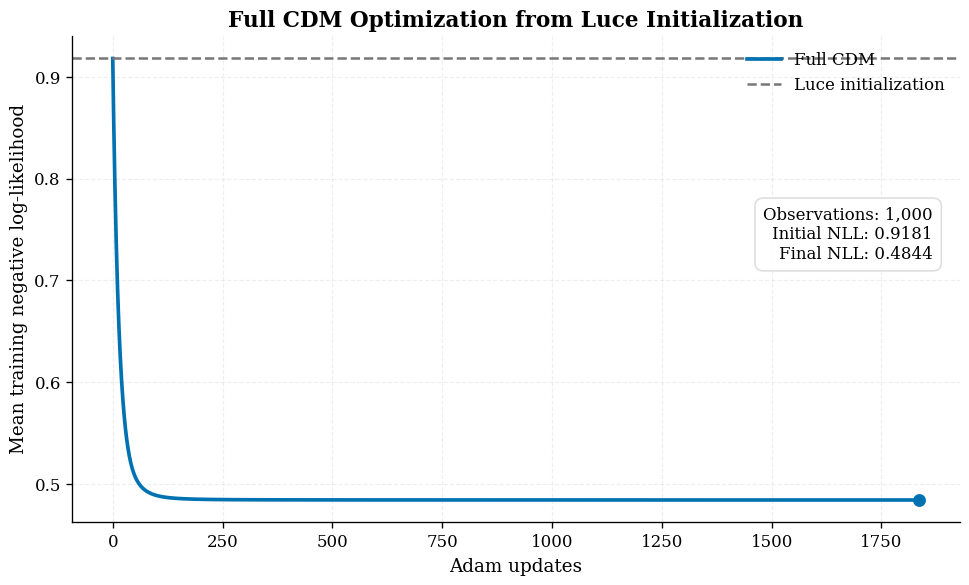

In [25]:
# Plot and save the full-CDM training loss from Luce initialization.

training_nll_history = np.asarray(
    cdm_fit.nll_history,
    dtype=float,
)

update_numbers = np.arange(
    len(training_nll_history)
)

figure, axis = plt.subplots(
    figsize=(8.0, 4.8),
    constrained_layout=True,
)

axis.plot(
    update_numbers,
    training_nll_history,
    color="#0072B2",
    linewidth=2.2,
    label="Full CDM",
)

axis.axhline(
    training_nll_history[0],
    color="#777777",
    linestyle="--",
    linewidth=1.5,
    label="Luce initialization",
)

axis.scatter(
    update_numbers[-1],
    training_nll_history[-1],
    color="#0072B2",
    s=45,
    zorder=3,
)

axis.set(
    xlabel="Adam updates",
    ylabel="Mean training negative log-likelihood",
    title="Full CDM Optimization from Luce Initialization",
)

axis.text(
    0.97,
    0.65,
    (
        f"Observations: {len(synthetic_data.choice_sets):,}\n"
        f"Initial NLL: {training_nll_history[0]:.4f}\n"
        f"Final NLL: {training_nll_history[-1]:.4f}"
    ),
    transform=axis.transAxes,
    ha="right",
    va="top",
    fontsize=10,
    bbox={
        "facecolor": "white",
        "edgecolor": "#DDDDDD",
        "alpha": 0.95,
        "boxstyle": "round,pad=0.5",
    },
)

axis.legend(loc="upper right")
axis.grid(alpha=0.2)

figure.savefig(
    FIGURE_DIRECTORY / "02_full_cdm_optimization.pdf",
    bbox_inches="tight",
)

plt.show()

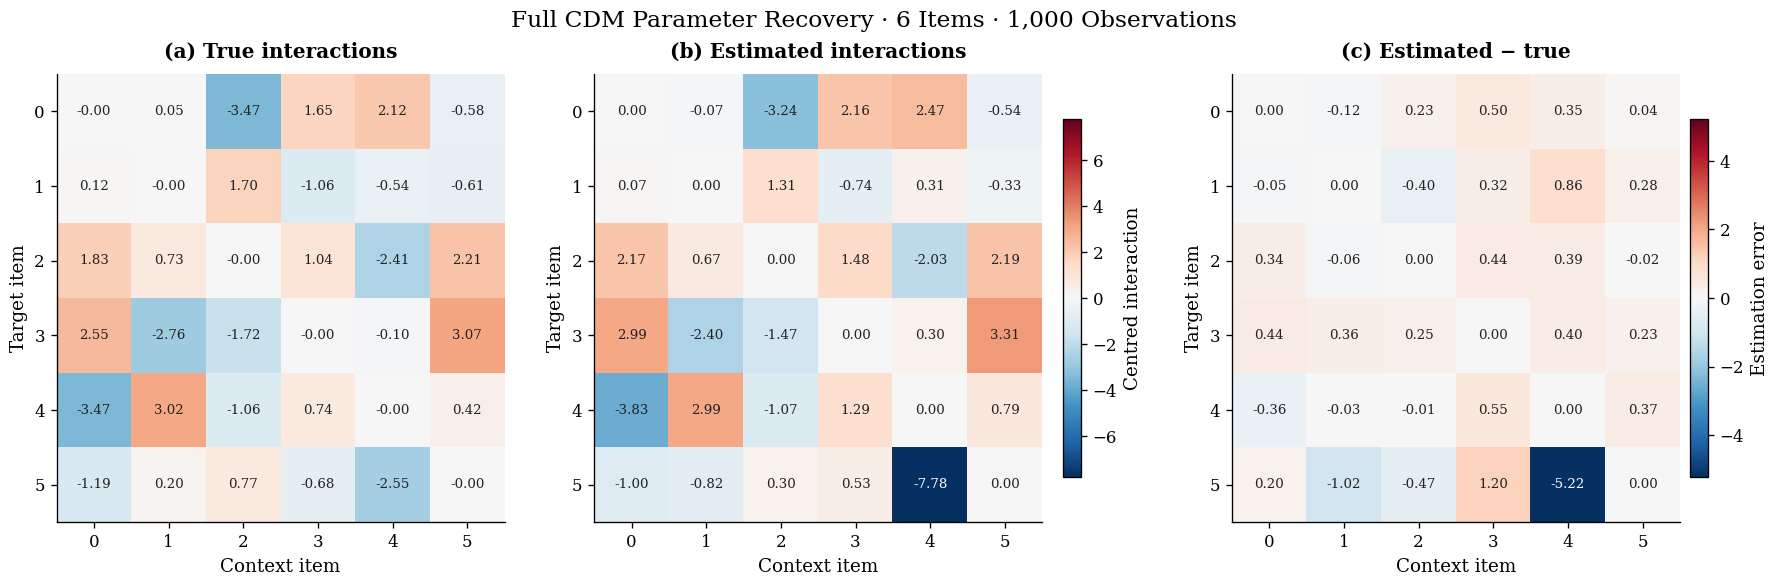

In [26]:
# Compare and save the true interactions, fitted interactions and estimation errors.

true_matrix_values = (
    cdm.center_cdm_parameters(true_interactions)
    .detach()
    .cpu()
    .numpy()
)

estimated_matrix_values = (
    cdm.center_cdm_parameters(estimated_interactions)
    .detach()
    .cpu()
    .numpy()
)

error_matrix_values = (
    estimated_matrix_values - true_matrix_values
)

interaction_limit = max(
    float(np.abs(true_matrix_values).max()),
    float(np.abs(estimated_matrix_values).max()),
    1e-12,
)

error_limit = max(
    float(np.abs(error_matrix_values).max()),
    1e-12,
)

figure, axes = plt.subplots(
    1,
    3,
    figsize=(15.0, 4.8),
    constrained_layout=True,
)

panel_settings = [
    (
        true_matrix_values,
        "(a) True interactions",
        interaction_limit,
    ),
    (
        estimated_matrix_values,
        "(b) Estimated interactions",
        interaction_limit,
    ),
    (
        error_matrix_values,
        "(c) Estimated − true",
        error_limit,
    ),
]

heatmaps = []

for axis, (matrix, title, limit) in zip(
    axes,
    panel_settings,
):
    heatmap = axis.imshow(
        matrix,
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit,
        interpolation="nearest",
        aspect="equal",
    )

    heatmaps.append(heatmap)

    axis.set_xticks(range(NUMBER_OF_ITEMS))
    axis.set_yticks(range(NUMBER_OF_ITEMS))
    axis.set_xlabel("Context item")
    axis.set_ylabel("Target item")
    axis.set_title(title, fontsize=12, pad=10)
    axis.grid(False)

    for row in range(NUMBER_OF_ITEMS):
        for column in range(NUMBER_OF_ITEMS):
            value = matrix[row, column]

            axis.text(
                column,
                row,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color=(
                    "white"
                    if abs(value) > 0.60 * limit
                    else "#222222"
                ),
            )

interaction_colourbar = figure.colorbar(
    heatmaps[0],
    ax=axes[:2].tolist(),
    shrink=0.8,
    pad=0.02,
)

interaction_colourbar.set_label("Centred interaction")

error_colourbar = figure.colorbar(
    heatmaps[2],
    ax=axes[2],
    shrink=0.8,
    pad=0.02,
)

error_colourbar.set_label("Estimation error")

figure.suptitle(
    (
        f"Full CDM Parameter Recovery · {NUMBER_OF_ITEMS} Items · "
        f"{len(synthetic_data.choice_sets):,} Observations"
    ),
    fontsize=14,
)

figure.savefig(
    FIGURE_DIRECTORY / "03_full_cdm_parameter_recovery.pdf",
    bbox_inches="tight",
)

plt.show()

In [27]:
# Measure recovery errors across the off-diagonal interaction parameters.

off_diagonal_mask = ~np.eye(NUMBER_OF_ITEMS, dtype=bool)
parameter_errors = error_matrix_values[off_diagonal_mask]

recovery_summary = pd.DataFrame({
    "Metric": [
        "Squared error (sum)",
        "Mean squared error",
        "Root mean squared error",
        "Maximum absolute error",
    ],
    "Value": [
        np.sum(parameter_errors**2),
        np.mean(parameter_errors**2),
        np.sqrt(np.mean(parameter_errors**2)),
        np.max(np.abs(parameter_errors)),
    ],
})

target_indices, context_indices = np.where(off_diagonal_mask)

parameter_error_table = pd.DataFrame({
    "Target item": target_indices,
    "Context item": context_indices,
    "True interaction": true_matrix_values[off_diagonal_mask],
    "Estimated interaction": estimated_matrix_values[off_diagonal_mask],
    "Absolute error": np.abs(parameter_errors),
}).sort_values("Absolute error", ascending=False)

display(recovery_summary.style.format({"Value": "{:.6f}"}))
display(
    parameter_error_table.head(5).style.format({
        "True interaction": "{:.4f}",
        "Estimated interaction": "{:.4f}",
        "Absolute error": "{:.4f}",
    })
)

,Metric,Value
0,Squared error (sum),33.200383
1,Mean squared error,1.106679
2,Root mean squared error,1.051988
3,Maximum absolute error,5.224316


,Target item,Context item,True interaction,Estimated interaction,Absolute error
29,5,4,-2.5529,-7.7772,5.2243
28,5,3,-0.6774,0.5264,1.2038
26,5,1,0.1985,-0.8200,1.0185
8,1,4,-0.5438,0.3149,0.8587
23,4,3,0.7366,1.2874,0.5508


In [28]:
# Inspect choices involving the target and context with the largest recovery error.

worst_entry = parameter_error_table.iloc[0]
target_item = int(worst_entry["Target item"])
context_item = int(worst_entry["Context item"])

choice_sets = synthetic_data.choice_sets
choice_mask = synthetic_data.choice_mask.bool()

target_present = (
    choice_sets.eq(target_item) & choice_mask
).any(dim=1)

context_present = (
    choice_sets.eq(context_item) & choice_mask
).any(dim=1)

both_present = target_present & context_present
target_chosen = synthetic_data.chosen_items.eq(target_item)

diagnostic_rows = []

for choice_set_size in range(2, NUMBER_OF_ITEMS + 1):
    selected_rows = (
        both_present
        & choice_mask.sum(dim=1).eq(choice_set_size)
    )
    observation_count = int(selected_rows.sum().item())
    target_choice_count = int(
        (selected_rows & target_chosen).sum().item()
    )

    diagnostic_rows.append({
        "Choice-set size": choice_set_size,
        "Both items present": observation_count,
        "Target chosen": target_choice_count,
        "Target choice rate": (
            target_choice_count / observation_count
            if observation_count else np.nan
        ),
    })

print(f"Target item: {target_item}; context item: {context_item}")
print(f"Total co-occurrences: {int(both_present.sum().item())}")
print(
    "Target chosen during co-occurrence:",
    int((both_present & target_chosen).sum().item()),
)

display(
    pd.DataFrame(diagnostic_rows).style.format({
        "Target choice rate": "{:.4f}",
    })
)

Target item: 5; context item: 4
Total co-occurrences: 309
Target chosen during co-occurrence: 0


,Choice-set size,Both items present,Target chosen,Target choice rate
0,2,21,0,0.0000
1,3,64,0,0.0000
2,4,113,0,0.0000
3,5,84,0,0.0000
4,6,27,0,0.0000


In [29]:
# Calculate expected target choices and the probability of zero choices under the true CDM.

target_item = 5
context_item = 4

choice_sets = synthetic_data.choice_sets
choice_mask = synthetic_data.choice_mask.bool()

target_positions = choice_sets.eq(target_item) & choice_mask
context_present = (
    choice_sets.eq(context_item) & choice_mask
).any(dim=1)

both_present = target_positions.any(dim=1) & context_present

with torch.no_grad():
    true_probabilities = cdm.cdm_choice_probabilities(
        interaction_matrix=true_interactions,
        choice_sets=choice_sets,
        choice_mask=choice_mask,
    )

    target_probabilities = (
        true_probabilities * target_positions
    ).sum(dim=1)

conditional_probabilities = (
    target_probabilities[both_present]
    .detach()
    .cpu()
    .numpy()
)

expected_target_choices = conditional_probabilities.sum()

with np.errstate(divide="ignore"):
    log_probability_of_zero = np.log1p(
        -conditional_probabilities
    ).sum()

probability_of_zero = np.exp(log_probability_of_zero)

observed_target_choices = int(
    (
        both_present
        & synthetic_data.chosen_items.eq(target_item)
    ).sum().item()
)

rare_choice_summary = pd.DataFrame({
    "Quantity": [
        "Observations containing both items",
        "Observed target choices",
        "Expected target choices under true CDM",
        "Probability of zero target choices",
    ],
    "Value": [
        int(both_present.sum().item()),
        observed_target_choices,
        expected_target_choices,
        probability_of_zero,
    ],
})

display(
    rare_choice_summary.style.format({
        "Value": "{:.6f}",
    })
)

,Quantity,Value
0,Observations containing both items,309.000000
1,Observed target choices,0.000000
2,Expected target choices under true CDM,3.241570
3,Probability of zero target choices,0.035679


In [30]:
# Evaluate training NLL along the direction suggested by the zero-choice diagnostic.

direction_rows = []

with torch.no_grad():
    base_interactions = cdm.center_cdm_parameters(
        estimated_interactions.detach().clone()
    )

    for decrease in [0.0, 1.0, 2.0, 5.0, 10.0, 20.0]:
        candidate_interactions = base_interactions.clone()
        candidate_interactions[target_item, context_item] -= decrease

        candidate_interactions = cdm.center_cdm_parameters(
            candidate_interactions
        )

        candidate_nll = cdm.average_cdm_negative_log_likelihood(
            interaction_matrix=candidate_interactions,
            choice_sets=synthetic_data.choice_sets,
            chosen_positions=synthetic_data.chosen_positions,
            choice_mask=synthetic_data.choice_mask,
        ).item()

        direction_rows.append({
            "Decrease before centering": decrease,
            "Centred target-context interaction": (
                candidate_interactions[
                    target_item, context_item
                ].item()
            ),
            "Training NLL": candidate_nll,
        })

direction_summary = pd.DataFrame(direction_rows)

direction_summary["NLL improvement over fitted matrix"] = (
    direction_summary.loc[0, "Training NLL"]
    - direction_summary["Training NLL"]
)

display(
    direction_summary.style.format({
        "Decrease before centering": "{:.1f}",
        "Centred target-context interaction": "{:.6f}",
        "Training NLL": "{:.12f}",
        "NLL improvement over fitted matrix": "{:.12f}",
    })
)

,Decrease before centering,Centred target-context interaction,Training NLL,NLL improvement over fitted matrix
0,0.0,-7.777229,0.484397758051,0.000000000000
1,1.0,-8.743895,0.484391669787,0.000006088265
2,2.0,-9.710562,0.484389429878,0.000008328173
3,5.0,-12.610562,0.484388191167,0.000009566884
4,10.0,-17.443895,0.484388126701,0.000009631350
5,20.0,-27.110562,0.484388126263,0.000009631788


### Diagnostic finding at 1,000 observations

Items 4 and 5 appeared together in 309 observations, but item 5
was never selected in those observations. Under the true CDM,
the expected number of such selections was 3.2416, and the
conditional probability of observing none was approximately 3.57%.

For the unrestricted, unregularized full CDM, decreasing the
interaction from context item 4 to target item 5 improves the
likelihood without attaining a finite optimum along this direction.
The optimizer's convergence flag therefore indicates satisfaction
of its numerical stopping criterion, rather than existence of a
finite maximum-likelihood estimate.

This interaction accounts for approximately 82% of the total
squared parameter error. We retain this run and investigate how
recovery and this diagnostic change as the observation count grows.

In [31]:
# Save the initial recovery results and finite-MLE diagnostics.

diagnostic_directory = (
    RESULT_DIRECTORY / "initial_1000_observation_diagnostics"
)
diagnostic_directory.mkdir(parents=True, exist_ok=True)

diagnostic_tables = {
    "parameter_recovery_metrics": recovery_summary,
    "parameter_errors": parameter_error_table,
    "rare_choice_summary": rare_choice_summary,
    "likelihood_direction": direction_summary,
}

for table_name, table in diagnostic_tables.items():
    table.to_csv(
        diagnostic_directory / f"{table_name}.csv",
        index=False,
    )

np.savez_compressed(
    diagnostic_directory / "interaction_matrices.npz",
    true_interactions=true_matrix_values,
    estimated_interactions=estimated_matrix_values,
)

print(f"Saved diagnostics to:\n{diagnostic_directory}")

Saved diagnostics to:
/Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/results/experiments/cdm_paper_reproduction/01_synthetic_recovery/initial_1000_observation_diagnostics


In [32]:
# Define repeated observation-scaling trials with a fixed true interaction matrix.

SCALING_OBSERVATION_COUNTS = (
    1_000,
    5_000,
    10_000,
    50_000,
)
SCALING_NUMBER_OF_RUNS = 10

scaling_true_interactions = true_interactions.detach().clone()

scaling_trial_plan = pd.DataFrame([
    {
        "Run": run_index + 1,
        "Number of items": NUMBER_OF_ITEMS,
        "Number of observations": observation_count,
        "Choice-set seed": SEED + 10_000 + 2 * run_index,
        "Choice-outcome seed": SEED + 10_001 + 2 * run_index,
    }
    for run_index in range(SCALING_NUMBER_OF_RUNS)
    for observation_count in SCALING_OBSERVATION_COUNTS
])

scaling_trial_plan.to_csv(
    RESULT_DIRECTORY / "observation_scaling_trial_plan.csv",
    index=False,
)

print(f"Total fits planned: {len(scaling_trial_plan)}")
print("True interaction matrix: fixed across all trials")
print("Choice-set sizes: 2 through 6")
display(scaling_trial_plan.head(8))

Total fits planned: 40
True interaction matrix: fixed across all trials
Choice-set sizes: 2 through 6


,Run,Number of items,Number of observations,Choice-set seed,Choice-outcome seed
0,1,6,1000,20270831,20270832
1,1,6,5000,20270831,20270832
2,1,6,10000,20270831,20270832
3,1,6,50000,20270831,20270832
4,2,6,1000,20270833,20270834
5,2,6,5000,20270833,20270834
6,2,6,10000,20270833,20270834
7,2,6,50000,20270833,20270834


In [33]:
# Smoke-test the scaling runner on two nested sample sizes.

import importlib
import cdm_paper_reproduction.experiments as paper_experiments

paper_experiments = importlib.reload(paper_experiments)

scaling_smoke_results = (
    paper_experiments.run_paper_cdm_recovery_scaling(
        true_interactions=scaling_true_interactions,
        observation_counts=(1_000, 5_000),
        number_of_runs=1,
        base_seed=SEED,
        maximum_epochs=5_000,
        checkpoint_path=(
            RESULT_DIRECTORY / "observation_scaling_smoke.csv"
        ),
    )
)

display(
    scaling_smoke_results[[
        "Number of observations",
        "Fit status",
        "Parameter RMSE",
        "Zero-choice separation pairs",
        "Optimizer converged",
        "Stopping reason",
        "Error message",
    ]]
)

Fit 1/2 | run=1 | observations=1,000 | separation pairs=0
Fit 2/2 | run=1 | observations=5,000 | separation pairs=0


,Number of observations,Fit status,Parameter RMSE,Zero-choice separation pairs,Optimizer converged,Stopping reason,Error message
0,1000,completed,0.2992,0,True,gradient tolerance reached,
1,5000,completed,0.1832,0,True,gradient tolerance reached,


In [34]:
# Run repeated recovery experiments across all planned observation counts.

scaling_results = (
    paper_experiments.run_paper_cdm_recovery_scaling(
        true_interactions=scaling_true_interactions,
        observation_counts=SCALING_OBSERVATION_COUNTS,
        number_of_runs=SCALING_NUMBER_OF_RUNS,
        base_seed=SEED,
        learning_rate=0.05,
        gradient_tolerance=1e-5,
        nll_tolerance=1e-9,
        patience=50,
        maximum_epochs=5_000,
        checkpoint_path=(
            RESULT_DIRECTORY / "observation_scaling_results.csv"
        ),
    )
)

print(f"\nRecorded trials: {len(scaling_results)}")
display(scaling_results["Fit status"].value_counts())

Fit 1/40 | run=1 | observations=1,000 | separation pairs=0
Fit 2/40 | run=1 | observations=5,000 | separation pairs=0
Fit 3/40 | run=1 | observations=10,000 | separation pairs=0
Fit 4/40 | run=1 | observations=50,000 | separation pairs=0
Fit 5/40 | run=2 | observations=1,000 | separation pairs=0
Fit 6/40 | run=2 | observations=5,000 | separation pairs=0
Fit 7/40 | run=2 | observations=10,000 | separation pairs=0
Fit 8/40 | run=2 | observations=50,000 | separation pairs=0
Fit 9/40 | run=3 | observations=1,000 | separation pairs=0
Fit 10/40 | run=3 | observations=5,000 | separation pairs=0
Fit 11/40 | run=3 | observations=10,000 | separation pairs=0
Fit 12/40 | run=3 | observations=50,000 | separation pairs=0
Fit 13/40 | run=4 | observations=1,000 | separation pairs=0
Fit 14/40 | run=4 | observations=5,000 | separation pairs=0
Fit 15/40 | run=4 | observations=10,000 | separation pairs=0
Fit 16/40 | run=4 | observations=50,000 | separation pairs=0
Fit 17/40 | run=5 | observations=1,000 | 

Fit status
completed    40
Name: count, dtype: int64

In [35]:
# Summarise recovery errors, numerical convergence, and separation across runs.

scaling_summary = (
    scaling_results
    .groupby("Number of observations", as_index=False)
    .agg(
        Trials=("Run", "size"),
        Completed=(
            "Fit status",
            lambda values: values.eq("completed").sum(),
        ),
        Failed=(
            "Fit status",
            lambda values: values.eq("failed").sum(),
        ),
        Optimizer_converged=(
            "Optimizer converged",
            lambda values: values.eq(True).sum(),
        ),
        Separation_flagged_runs=(
            "Zero-choice separation detected",
            "sum",
        ),
        Mean_squared_parameter_error=(
            "Squared parameter error",
            "mean",
        ),
        Squared_parameter_error_std=(
            "Squared parameter error",
            "std",
        ),
        Mean_RMSE=("Parameter RMSE", "mean"),
        RMSE_std=("Parameter RMSE", "std"),
        Mean_epochs=("Epochs", "mean"),
        Mean_CDM_runtime_seconds=(
            "CDM runtime (seconds)",
            "mean",
        ),
    )
)

scaling_summary.to_csv(
    RESULT_DIRECTORY / "observation_scaling_summary.csv",
    index=False,
)

display(
    scaling_summary.style.format({
        "Number of observations": "{:,}",
        "Mean_squared_parameter_error": "{:.6f}",
        "Squared_parameter_error_std": "{:.6f}",
        "Mean_RMSE": "{:.6f}",
        "RMSE_std": "{:.6f}",
        "Mean_epochs": "{:.1f}",
        "Mean_CDM_runtime_seconds": "{:.3f}",
    })
)

,Number of observations,Trials,Completed,Failed,Optimizer_converged,Separation_flagged_runs,Mean_squared_parameter_error,Squared_parameter_error_std,Mean_RMSE,RMSE_std,Mean_epochs,Mean_CDM_runtime_seconds
0,"1,000",10,10,0,10,0,8.903395,5.408000,0.523288,0.159686,662.0,1.001
1,"5,000",10,10,0,10,0,1.320581,0.513035,0.206828,0.037145,595.4,2.415
2,"10,000",10,10,0,10,0,0.637335,0.263676,0.142261,0.033437,597.8,4.503
3,"50,000",10,10,0,10,0,0.151557,0.061743,0.069638,0.014999,577.1,22.330


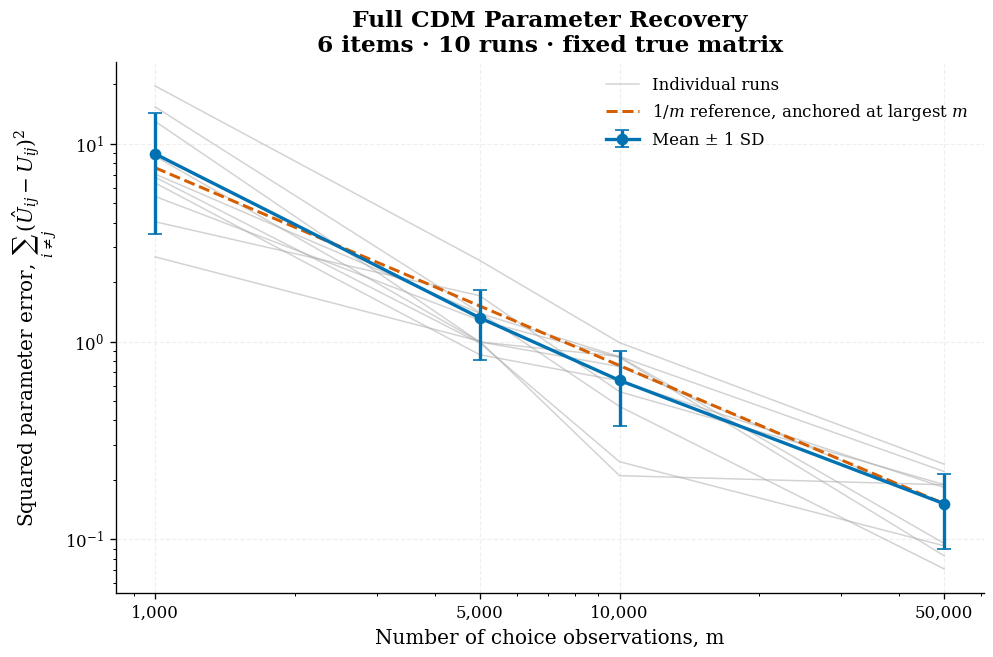

In [36]:
# Plot squared parameter recovery error with individual runs and an inverse-sample-size reference.

summary = scaling_summary.sort_values("Number of observations")

observation_counts = summary["Number of observations"].to_numpy()
mean_squared_errors = (
    summary["Mean_squared_parameter_error"].to_numpy()
)
squared_error_std = (
    summary["Squared_parameter_error_std"].to_numpy()
)

inverse_sample_reference = (
    mean_squared_errors[-1]
    * observation_counts[-1]
    / observation_counts
)

with plt.rc_context({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "pdf.fonttype": 42,
}):
    figure, axis = plt.subplots(
        figsize=(8.2, 5.4),
        layout="constrained",
    )

    for run_number, run_results in scaling_results.groupby("Run"):
        run_results = run_results.sort_values(
            "Number of observations"
        )

        axis.plot(
            run_results["Number of observations"],
            run_results["Squared parameter error"],
            color="0.65",
            linewidth=0.9,
            alpha=0.5,
            label="Individual runs" if run_number == 1 else None,
            zorder=1,
        )

    axis.errorbar(
        observation_counts,
        mean_squared_errors,
        yerr=squared_error_std,
        color="#0072B2",
        marker="o",
        markersize=6,
        linewidth=2,
        capsize=4,
        label="Mean ± 1 SD",
        zorder=3,
    )

    axis.plot(
        observation_counts,
        inverse_sample_reference,
        color="#D55E00",
        linestyle="--",
        linewidth=1.8,
        label=r"$1/m$ reference, anchored at largest $m$",
        zorder=2,
    )

    axis.set_xscale("log")
    axis.set_yscale("log")
    axis.set_xticks(
        observation_counts,
        labels=[f"{count:,}" for count in observation_counts],
    )

    axis.set_xlabel("Number of choice observations, m")
    axis.set_ylabel(
        r"Squared parameter error, $\sum_{i\ne j}(\hat U_{ij}-U_{ij})^2$"
    )
    axis.set_title(
        "Full CDM Parameter Recovery\n"
        f"{NUMBER_OF_ITEMS} items · "
        f"{SCALING_NUMBER_OF_RUNS} runs · fixed true matrix"
    )

    axis.grid(True, which="major", alpha=0.2)
    axis.grid(False, which="minor")
    axis.spines[["top", "right"]].set_visible(False)
    axis.legend(frameon=False, fontsize=10)

    figure.savefig(
        FIGURE_DIRECTORY / "04_parameter_recovery_scaling.pdf",
        bbox_inches="tight",
    )

    plt.show()

For a fixed six-item CDM, the mean squared parameter error decreased from 8.90 to 0.152 as the observation count increased from 1,000 to 50,000. Across ten runs, the observed trend was approximately consistent with inverse-sample-size decay.

In [37]:
# Configure and record the extended six-item recovery experiment.

import json
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch

from cdm_paper_reproduction.experiments import (
    run_paper_cdm_recovery_scaling,
)

EXTENDED_OBSERVATION_COUNTS = (
    1_000,
    1_500,
    2_000,
    3_000,
    5_000,
    7_500,
    10_000,
    15_000,
    20_000,
    30_000,
    50_000,
    75_000,
    100_000,
)

EXTENDED_NUMBER_OF_RUNS = 10
EXTENDED_BASE_SEED = SEED

extended_true_interactions = (
    scaling_true_interactions.detach().clone()
)

assert extended_true_interactions.shape == (6, 6)
assert torch.isfinite(extended_true_interactions).all().item()

extended_optimizer_settings = {
    "learning_rate": 0.05,
    "gradient_tolerance": 1e-5,
    "nll_tolerance": 1e-9,
    "patience": 50,
    "maximum_epochs": 5_000,
}

extended_run_stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

EXTENDED_RESULT_DIRECTORY = (
    RESULT_DIRECTORY / f"extended_100k_{extended_run_stamp}"
)
EXTENDED_RESULT_DIRECTORY.mkdir(parents=True, exist_ok=False)

extended_settings = {
    "number_of_items": 6,
    "number_of_runs": EXTENDED_NUMBER_OF_RUNS,
    "observation_counts": list(EXTENDED_OBSERVATION_COUNTS),
    "base_seed": int(EXTENDED_BASE_SEED),
    "dtype": str(extended_true_interactions.dtype),
    "device": str(extended_true_interactions.device),
    "fixed_true_matrix": True,
    "nested_datasets_within_each_run": True,
    "maximum_generated_pool_size": 100_000,
    "grid_status": "Our chosen grid; exact author grid unverified",
    "optimizer": extended_optimizer_settings,
}

(EXTENDED_RESULT_DIRECTORY / "settings.json").write_text(
    json.dumps(extended_settings, indent=2),
    encoding="utf-8",
)

np.save(
    EXTENDED_RESULT_DIRECTORY / "true_interactions.npy",
    extended_true_interactions.cpu().numpy(),
)

display(
    pd.DataFrame({
        "Number of observations": EXTENDED_OBSERVATION_COUNTS,
        "Runs": EXTENDED_NUMBER_OF_RUNS,
    })
)

print(
    "Total fits:",
    len(EXTENDED_OBSERVATION_COUNTS) * EXTENDED_NUMBER_OF_RUNS,
)
print("Results directory:", EXTENDED_RESULT_DIRECTORY)

,Number of observations,Runs
0,1000,10
1,1500,10
2,2000,10
3,3000,10
4,5000,10
5,7500,10
6,10000,10
7,15000,10
8,20000,10
9,30000,10


Total fits: 130
Results directory: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/results/experiments/cdm_paper_reproduction/01_synthetic_recovery/extended_100k_20261013T142308_572830Z


In [38]:
# Run the extended recovery experiment and save its diagnostic summary.

extended_scaling_results = run_paper_cdm_recovery_scaling(
    true_interactions=extended_true_interactions,
    observation_counts=EXTENDED_OBSERVATION_COUNTS,
    number_of_runs=EXTENDED_NUMBER_OF_RUNS,
    base_seed=EXTENDED_BASE_SEED,
    checkpoint_path=(
        EXTENDED_RESULT_DIRECTORY / "observation_scaling_results.csv"
    ),
    **extended_optimizer_settings,
)

extended_scaling_results.to_csv(
    EXTENDED_RESULT_DIRECTORY / "observation_scaling_results.csv",
    index=False,
)

extended_summary_data = extended_scaling_results.copy()

extended_summary_data["Finite recovery result"] = np.isfinite(
    extended_summary_data["Squared parameter error"]
)

extended_scaling_summary = (
    extended_summary_data.groupby(
        "Number of observations",
        as_index=False,
        sort=True,
    )
    .agg(
        Trials=("Run", "size"),
        Completed=("Finite recovery result", "sum"),
        Optimizer_converged=("Optimizer converged", "sum"),
        Separation_flagged_runs=(
            "Zero-choice separation detected",
            "sum",
        ),
        Mean_squared_parameter_error=(
            "Squared parameter error",
            "mean",
        ),
        Squared_parameter_error_std=(
            "Squared parameter error",
            "std",
        ),
        Mean_RMSE=("Parameter RMSE", "mean"),
        RMSE_std=("Parameter RMSE", "std"),
        Mean_epochs=("Epochs", "mean"),
        Mean_CDM_runtime_seconds=("CDM runtime (seconds)", "mean"),
    )
)

extended_scaling_summary.insert(
    3,
    "Failed",
    extended_scaling_summary["Trials"]
    - extended_scaling_summary["Completed"],
)

extended_scaling_summary.to_csv(
    EXTENDED_RESULT_DIRECTORY / "observation_scaling_summary.csv",
    index=False,
)

display(
    extended_scaling_summary.style.format({
        "Number of observations": "{:,.0f}",
        "Trials": "{:.0f}",
        "Completed": "{:.0f}",
        "Failed": "{:.0f}",
        "Optimizer_converged": "{:.0f}",
        "Separation_flagged_runs": "{:.0f}",
        "Mean_squared_parameter_error": "{:.6f}",
        "Squared_parameter_error_std": "{:.6f}",
        "Mean_RMSE": "{:.6f}",
        "RMSE_std": "{:.6f}",
        "Mean_epochs": "{:.1f}",
        "Mean_CDM_runtime_seconds": "{:.3f}",
    })
)

print("\nFit status counts:")
print(extended_scaling_results["Fit status"].value_counts(dropna=False))

print("\nSaved results:", EXTENDED_RESULT_DIRECTORY)

Fit 1/130 | run=1 | observations=1,000 | separation pairs=0
Fit 2/130 | run=1 | observations=1,500 | separation pairs=0
Fit 3/130 | run=1 | observations=2,000 | separation pairs=0
Fit 4/130 | run=1 | observations=3,000 | separation pairs=0
Fit 5/130 | run=1 | observations=5,000 | separation pairs=0
Fit 6/130 | run=1 | observations=7,500 | separation pairs=0
Fit 7/130 | run=1 | observations=10,000 | separation pairs=0
Fit 8/130 | run=1 | observations=15,000 | separation pairs=0
Fit 9/130 | run=1 | observations=20,000 | separation pairs=0
Fit 10/130 | run=1 | observations=30,000 | separation pairs=0
Fit 11/130 | run=1 | observations=50,000 | separation pairs=0
Fit 12/130 | run=1 | observations=75,000 | separation pairs=0
Fit 13/130 | run=1 | observations=100,000 | separation pairs=0
Fit 14/130 | run=2 | observations=1,000 | separation pairs=0
Fit 15/130 | run=2 | observations=1,500 | separation pairs=0
Fit 16/130 | run=2 | observations=2,000 | separation pairs=0
Fit 17/130 | run=2 | obse

,Number of observations,Trials,Completed,Failed,Optimizer_converged,Separation_flagged_runs,Mean_squared_parameter_error,Squared_parameter_error_std,Mean_RMSE,RMSE_std,Mean_epochs,Mean_CDM_runtime_seconds
0,"1,000",10,10,0,10,0,8.903395,5.408000,0.523288,0.159686,662.0,0.957
1,"1,500",10,10,0,10,0,5.451864,2.578905,0.414744,0.103901,647.0,1.004
2,"2,000",10,10,0,10,0,3.871295,1.696190,0.350200,0.084346,624.8,1.081
3,"3,000",10,10,0,10,0,2.105288,0.866022,0.260191,0.052460,620.4,1.310
4,"5,000",10,10,0,10,0,1.320581,0.513035,0.206828,0.037145,595.4,1.931
5,"7,500",10,10,0,10,0,0.922104,0.347368,0.172103,0.035232,600.0,2.802
6,"10,000",10,10,0,10,0,0.637335,0.263676,0.142261,0.033437,597.8,3.776
7,"15,000",10,10,0,10,0,0.484692,0.175785,0.124985,0.024383,585.5,5.098
8,"20,000",10,10,0,10,0,0.338307,0.152991,0.103723,0.024001,589.2,6.870
9,"30,000",10,10,0,10,0,0.242919,0.100190,0.087951,0.020055,585.1,10.143



Fit status counts:
Fit status
completed    130
Name: count, dtype: int64

Saved results: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/results/experiments/cdm_paper_reproduction/01_synthetic_recovery/extended_100k_20261013T142308_572830Z


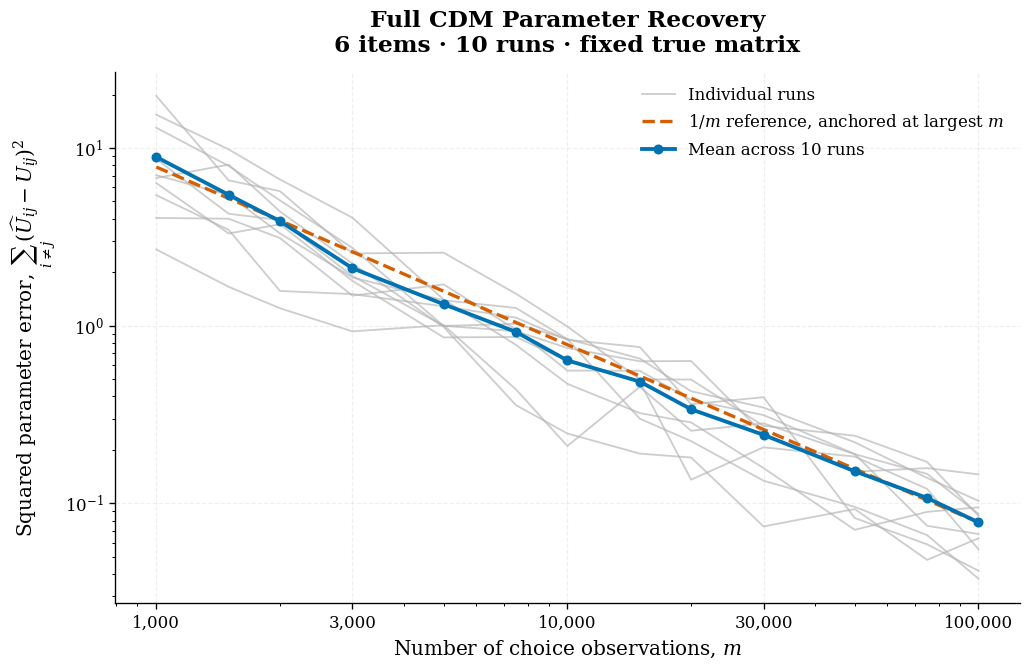

Saved figure: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/docs/thesis/images/experiments/cdm_paper_reproduction/01_synthetic_recovery/extended_100k_20261013T142308_572830Z/06_parameter_recovery_scaling_100k.pdf


In [40]:
# Plot and save all extended recovery runs with an inverse-sample reference.

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

extended_plot_data = (
    extended_scaling_results.pivot(
        index="Number of observations",
        columns="Run",
        values="Squared parameter error",
    )
    .sort_index()
)

assert np.isfinite(extended_plot_data.to_numpy()).all()
assert (extended_plot_data.to_numpy() > 0).all(), (
    "Logarithmic plotting requires strictly positive errors."
)

extended_counts = extended_plot_data.index.to_numpy()
extended_mean_error = extended_plot_data.mean(axis=1).to_numpy()

extended_reference = (
    extended_mean_error[-1]
    * extended_counts[-1]
    / extended_counts
)

extended_figure_directory = (
    FIGURE_DIRECTORY / EXTENDED_RESULT_DIRECTORY.name
)
extended_figure_directory.mkdir(parents=True, exist_ok=True)

with plt.rc_context({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "pdf.fonttype": 42,
}):
    figure, axis = plt.subplots(
        figsize=(8.5, 5.5),
        constrained_layout=True,
    )

    for position, run in enumerate(extended_plot_data.columns):
        axis.plot(
            extended_counts,
            extended_plot_data[run],
            color="0.70",
            linewidth=1.1,
            alpha=0.65,
            label="Individual runs" if position == 0 else None,
        )

    axis.plot(
        extended_counts,
        extended_reference,
        color="#D55E00",
        linestyle="--",
        linewidth=2,
        label=r"$1/m$ reference, anchored at largest $m$",
    )

    axis.plot(
        extended_counts,
        extended_mean_error,
        color="#0072B2",
        marker="o",
        markersize=5,
        linewidth=2.3,
        label="Mean across 10 runs",
        zorder=3,
    )

    axis.set_xscale("log")
    axis.set_yscale("log")
    axis.set_xticks([1_000, 3_000, 10_000, 30_000, 100_000])
    axis.xaxis.set_major_formatter(
        FuncFormatter(lambda value, _: f"{value:,.0f}")
    )

    axis.set_xlabel(r"Number of choice observations, $m$")
    axis.set_ylabel(
        r"Squared parameter error, $\sum_{i\ne j}(\widehat{U}_{ij}-U_{ij})^2$"
    )
    axis.set_title(
        "Full CDM Parameter Recovery\n"
        "6 items · 10 runs · fixed true matrix",
        pad=12,
    )

    axis.grid(which="major", alpha=0.20, linestyle="--")
    axis.spines[["top", "right"]].set_visible(False)
    axis.legend(frameon=False, fontsize=10)

    extended_plot_path = (
        extended_figure_directory
        / "06_parameter_recovery_scaling_100k.pdf"
    )

    figure.savefig(extended_plot_path, bbox_inches="tight")
    plt.show()

print("Saved figure:", extended_plot_path)

In [41]:
# Summarise optimization cost and diagnostics across the extended runs.

extended_cost_data = extended_scaling_results.copy()

cost_columns = [
    "CDM runtime (seconds)",
    "Epochs",
]

assert np.isfinite(
    extended_cost_data[cost_columns].to_numpy(dtype=float)
).all(), "Some runtime or epoch values are missing; inspect those trials."

extended_cost_summary = (
    extended_cost_data.groupby(
        "Number of observations",
        as_index=False,
        sort=True,
    )
    .agg(
        Runs=("Run", "size"),
        Mean_runtime_seconds=("CDM runtime (seconds)", "mean"),
        Runtime_std_seconds=("CDM runtime (seconds)", "std"),
        Mean_epochs=("Epochs", "mean"),
        Epochs_std=("Epochs", "std"),
        Optimizer_converged=("Optimizer converged", "sum"),
        Separation_flagged_runs=(
            "Zero-choice separation detected",
            "sum",
        ),
    )
)

extended_cost_summary.to_csv(
    EXTENDED_RESULT_DIRECTORY / "optimization_cost_summary.csv",
    index=False,
)

display(
    extended_cost_summary.style.format({
        "Number of observations": "{:,.0f}",
        "Runs": "{:.0f}",
        "Mean_runtime_seconds": "{:.3f}",
        "Runtime_std_seconds": "{:.3f}",
        "Mean_epochs": "{:.1f}",
        "Epochs_std": "{:.1f}",
        "Optimizer_converged": "{:.0f}",
        "Separation_flagged_runs": "{:.0f}",
    })
)

,Number of observations,Runs,Mean_runtime_seconds,Runtime_std_seconds,Mean_epochs,Epochs_std,Optimizer_converged,Separation_flagged_runs
0,"1,000",10,0.957,0.299,662.0,88.7,10,0
1,"1,500",10,1.004,0.304,647.0,100.5,10,0
2,"2,000",10,1.081,0.331,624.8,65.2,10,0
3,"3,000",10,1.310,0.221,620.4,48.1,10,0
4,"5,000",10,1.931,0.202,595.4,54.3,10,0
5,"7,500",10,2.802,0.282,600.0,37.2,10,0
6,"10,000",10,3.776,0.349,597.8,32.5,10,0
7,"15,000",10,5.098,0.572,585.5,34.9,10,0
8,"20,000",10,6.870,0.949,589.2,25.0,10,0
9,"30,000",10,10.143,1.879,585.1,30.3,10,0


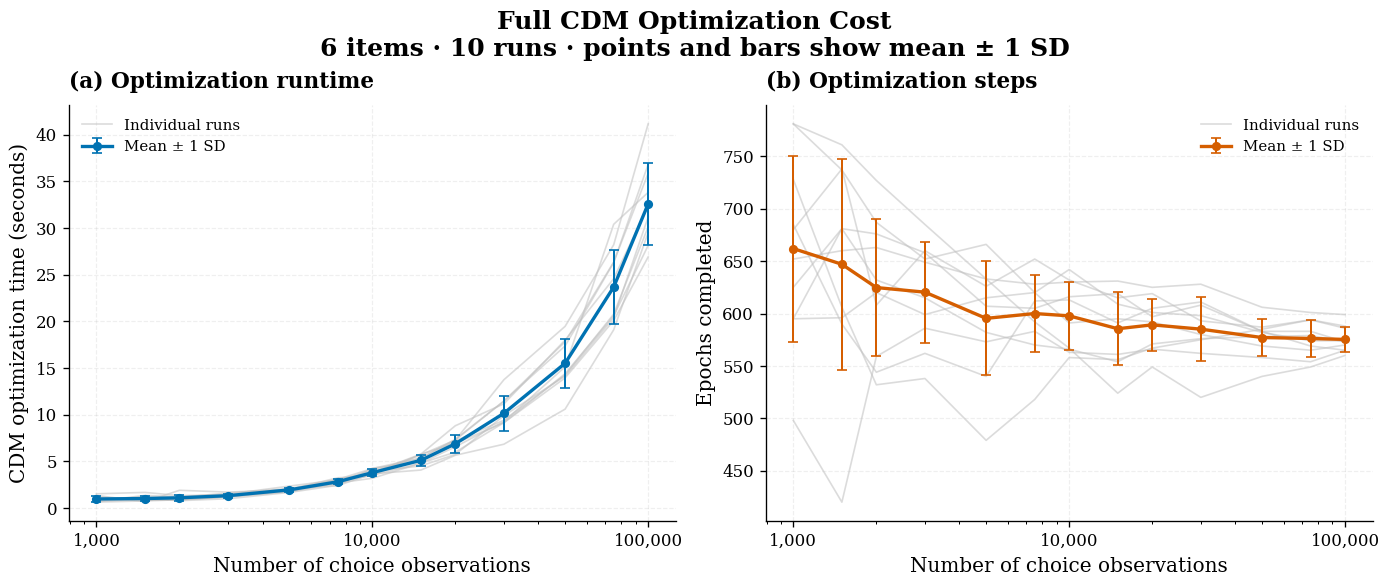

Saved figure: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/docs/thesis/images/experiments/cdm_paper_reproduction/01_synthetic_recovery/extended_100k_20261013T142308_572830Z/07_optimization_cost_scaling_100k.pdf


In [42]:
# Plot and save CDM optimization runtime and epochs against sample size.

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

extended_figure_directory = (
    FIGURE_DIRECTORY / EXTENDED_RESULT_DIRECTORY.name
)
extended_figure_directory.mkdir(parents=True, exist_ok=True)

cost_plot_settings = [
    {
        "raw": "CDM runtime (seconds)",
        "mean": "Mean_runtime_seconds",
        "std": "Runtime_std_seconds",
        "title": "(a) Optimization runtime",
        "ylabel": "CDM optimization time (seconds)",
        "colour": "#0072B2",
    },
    {
        "raw": "Epochs",
        "mean": "Mean_epochs",
        "std": "Epochs_std",
        "title": "(b) Optimization steps",
        "ylabel": "Epochs completed",
        "colour": "#D55E00",
    },
]

with plt.rc_context({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "pdf.fonttype": 42,
}):
    figure, axes = plt.subplots(
        1,
        2,
        figsize=(11.5, 4.8),
        constrained_layout=True,
    )

    for axis, settings in zip(axes, cost_plot_settings):
        for position, (_, run_data) in enumerate(
            extended_cost_data.groupby("Run", sort=True)
        ):
            run_data = run_data.sort_values(
                "Number of observations"
            )

            axis.plot(
                run_data["Number of observations"],
                run_data[settings["raw"]],
                color="0.75",
                linewidth=1,
                alpha=0.55,
                label="Individual runs" if position == 0 else None,
            )

        axis.errorbar(
            extended_cost_summary["Number of observations"],
            extended_cost_summary[settings["mean"]],
            yerr=extended_cost_summary[settings["std"]],
            color=settings["colour"],
            marker="o",
            markersize=4.5,
            linewidth=2,
            elinewidth=1.2,
            capsize=3,
            label="Mean ± 1 SD",
            zorder=3,
        )

        axis.set_xscale("log")
        axis.set_xticks([1_000, 10_000, 100_000])
        axis.xaxis.set_major_formatter(
            FuncFormatter(lambda value, _: f"{value:,.0f}")
        )

        axis.set_xlabel("Number of choice observations")
        axis.set_ylabel(settings["ylabel"])
        axis.set_title(settings["title"], loc="left", pad=10)
        axis.grid(which="major", alpha=0.20, linestyle="--")
        axis.spines[["top", "right"]].set_visible(False)
        axis.legend(frameon=False, fontsize=9)

    figure.suptitle(
        "Full CDM Optimization Cost\n"
        "6 items · 10 runs · points and bars show mean ± 1 SD",
        fontsize=15,
        fontweight="bold",
    )

    extended_cost_plot_path = (
        extended_figure_directory
        / "07_optimization_cost_scaling_100k.pdf"
    )

    figure.savefig(
        extended_cost_plot_path,
        bbox_inches="tight",
    )

    plt.show()

print("Saved figure:", extended_cost_plot_path)

In [43]:
# Export the final recovery table and diagnostic counts for Overleaf.

extended_table_directory = (
    TABLE_DIRECTORY / EXTENDED_RESULT_DIRECTORY.name
)
extended_table_directory.mkdir(parents=True, exist_ok=True)

final_recovery_data = (
    extended_scaling_summary.merge(
        extended_cost_summary[
            [
                "Number of observations",
                "Mean_runtime_seconds",
                "Runtime_std_seconds",
            ]
        ],
        on="Number of observations",
        how="left",
        validate="one_to_one",
    )
    .sort_values("Number of observations")
)

final_recovery_data.to_csv(
    EXTENDED_RESULT_DIRECTORY / "final_recovery_summary.csv",
    index=False,
)

final_recovery_table = pd.DataFrame({
    "Observations": final_recovery_data[
        "Number of observations"
    ].map(lambda value: f"{value:,.0f}"),
    "Fits": [
        f"{int(done)}/{int(total)}"
        for done, total in zip(
            final_recovery_data["Completed"],
            final_recovery_data["Trials"],
        )
    ],
    "Conv.": final_recovery_data[
        "Optimizer_converged"
    ].map(lambda value: f"{value:.0f}"),
    "SSE": [
        rf"${mean:.4f} \pm {std:.4f}$"
        for mean, std in zip(
            final_recovery_data["Mean_squared_parameter_error"],
            final_recovery_data["Squared_parameter_error_std"],
        )
    ],
    "RMSE": [
        rf"${mean:.4f} \pm {std:.4f}$"
        for mean, std in zip(
            final_recovery_data["Mean_RMSE"],
            final_recovery_data["RMSE_std"],
        )
    ],
    "Time (s)": [
        rf"${mean:.2f} \pm {std:.2f}$"
        for mean, std in zip(
            final_recovery_data["Mean_runtime_seconds"],
            final_recovery_data["Runtime_std_seconds"],
        )
    ],
})

final_table_path = (
    extended_table_directory / "synthetic_recovery_summary.tex"
)

final_recovery_table.to_latex(
    final_table_path,
    index=False,
    escape=False,
    column_format="rrrrrr",
    caption=(
        "Full CDM recovery for a fixed six-item interaction matrix. "
        "Error and runtime entries report mean plus or minus one "
        "standard deviation across runs. SSE is the sum of squared "
        "off-diagonal parameter errors. Fits counts finite recovery "
        "results; Conv. counts optimizer-reported convergence. "
        "Runtime includes CDM optimization only."
    ),
    label="tab:paper-synthetic-recovery",
)

extended_scaling_summary[
    [
        "Number of observations",
        "Trials",
        "Completed",
        "Failed",
        "Optimizer_converged",
        "Separation_flagged_runs",
    ]
].to_csv(
    EXTENDED_RESULT_DIRECTORY / "final_fit_diagnostics.csv",
    index=False,
)

display(final_recovery_table)
print("Saved LaTeX table:", final_table_path)

,Observations,Fits,Conv.,SSE,RMSE,Time (s)
0,"1,000",10/10,10,$8.9034 \pm 5.4080$,$0.5233 \pm 0.1597$,$0.96 \pm 0.30$
1,"1,500",10/10,10,$5.4519 \pm 2.5789$,$0.4147 \pm 0.1039$,$1.00 \pm 0.30$
2,"2,000",10/10,10,$3.8713 \pm 1.6962$,$0.3502 \pm 0.0843$,$1.08 \pm 0.33$
3,"3,000",10/10,10,$2.1053 \pm 0.8660$,$0.2602 \pm 0.0525$,$1.31 \pm 0.22$
4,"5,000",10/10,10,$1.3206 \pm 0.5130$,$0.2068 \pm 0.0371$,$1.93 \pm 0.20$
5,"7,500",10/10,10,$0.9221 \pm 0.3474$,$0.1721 \pm 0.0352$,$2.80 \pm 0.28$
6,"10,000",10/10,10,$0.6373 \pm 0.2637$,$0.1423 \pm 0.0334$,$3.78 \pm 0.35$
7,"15,000",10/10,10,$0.4847 \pm 0.1758$,$0.1250 \pm 0.0244$,$5.10 \pm 0.57$
8,"20,000",10/10,10,$0.3383 \pm 0.1530$,$0.1037 \pm 0.0240$,$6.87 \pm 0.95$
9,"30,000",10/10,10,$0.2429 \pm 0.1002$,$0.0880 \pm 0.0201$,$10.14 \pm 1.88$


Saved LaTeX table: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/docs/thesis/tables/experiments/cdm_paper_reproduction/01_synthetic_recovery/extended_100k_20261013T142308_572830Z/synthetic_recovery_summary.tex


In [44]:
# Record the experiment findings and limitations using the computed results.

from IPython.display import Markdown, display

ordered_recovery = extended_scaling_summary.sort_values(
    "Number of observations"
)

first_result = ordered_recovery.iloc[0]
last_result = ordered_recovery.iloc[-1]

total_trials = int(ordered_recovery["Trials"].sum())
completed_trials = int(ordered_recovery["Completed"].sum())
failed_trials = int(ordered_recovery["Failed"].sum())
converged_trials = int(
    ordered_recovery["Optimizer_converged"].sum()
)
flagged_trials = int(
    ordered_recovery["Separation_flagged_runs"].sum()
)

endpoint_trend = (
    "decreased"
    if last_result["Mean_squared_parameter_error"]
    < first_result["Mean_squared_parameter_error"]
    else "did not decrease"
)

recovery_conclusion = f"""
## Synthetic recovery: findings and limitations

### Experimental setup

- Fixed true interaction matrix for six items.
- {EXTENDED_NUMBER_OF_RUNS} repeated datasets at each of
  {len(EXTENDED_OBSERVATION_COUNTS)} sample sizes.
- Sample sizes range from
  {int(first_result["Number of observations"]):,} to
  {int(last_result["Number of observations"]):,}.
- Within each run, smaller datasets are prefixes of the same
  generated pool.
- Full CDM estimation uses Luce-based initialization and Adam.

### Results

- Finite recovery results: {completed_trials}/{total_trials}.
- Trials without finite recovery results: {failed_trials}.
- Optimizer-reported convergence: {converged_trials}/{total_trials}.
- Zero-choice separation flags: {flagged_trials}/{total_trials}.
- Mean squared parameter error {endpoint_trend} from
  {first_result["Mean_squared_parameter_error"]:.6f} at the smallest
  sample size to
  {last_result["Mean_squared_parameter_error"]:.6f} at the largest.
- Mean parameter RMSE was {first_result["Mean_RMSE"]:.6f} at the
  smallest sample size and {last_result["Mean_RMSE"]:.6f} at the largest.

### Interpretation and limitations

- Squared parameter error is the sum of squared differences between
  centred true and estimated off-diagonal interactions.
- The inverse-sample-size reference is anchored at the largest sample
  size; agreement at that endpoint is by construction.
- Standard deviations describe variation across runs, conditional
  on the fixed true matrix.
- Optimizer convergence does not certify existence of a finite MLE.
- The zero-choice diagnostic does not detect every possible
  separation or identifiability problem.
- The initial 1,000-observation separation example is retained
  separately from this repeated experiment.
- This is a reproduction of the recovery experiment's main idea
  using our documented sample grid, not a verified exact replication
  of the authors' implementation.
- These empirical results do not establish a uniform performance
  guarantee over all possible true parameter matrices.
"""

conclusion_path = (
    EXTENDED_RESULT_DIRECTORY / "synthetic_recovery_conclusion.md"
)
conclusion_path.write_text(
    recovery_conclusion.strip() + "\n",
    encoding="utf-8",
)

display(Markdown(recovery_conclusion))
print("Saved conclusion:", conclusion_path)


## Synthetic recovery: findings and limitations

### Experimental setup

- Fixed true interaction matrix for six items.
- 10 repeated datasets at each of
  13 sample sizes.
- Sample sizes range from
  1,000 to
  100,000.
- Within each run, smaller datasets are prefixes of the same
  generated pool.
- Full CDM estimation uses Luce-based initialization and Adam.

### Results

- Finite recovery results: 130/130.
- Trials without finite recovery results: 0.
- Optimizer-reported convergence: 130/130.
- Zero-choice separation flags: 0/130.
- Mean squared parameter error decreased from
  8.903395 at the smallest
  sample size to
  0.078151 at the largest.
- Mean parameter RMSE was 0.523288 at the
  smallest sample size and 0.050075 at the largest.

### Interpretation and limitations

- Squared parameter error is the sum of squared differences between
  centred true and estimated off-diagonal interactions.
- The inverse-sample-size reference is anchored at the largest sample
  size; agreement at that endpoint is by construction.
- Standard deviations describe variation across runs, conditional
  on the fixed true matrix.
- Optimizer convergence does not certify existence of a finite MLE.
- The zero-choice diagnostic does not detect every possible
  separation or identifiability problem.
- The initial 1,000-observation separation example is retained
  separately from this repeated experiment.
- This is a reproduction of the recovery experiment's main idea
  using our documented sample grid, not a verified exact replication
  of the authors' implementation.
- These empirical results do not establish a uniform performance
  guarantee over all possible true parameter matrices.


Saved conclusion: /Users/zsres/Documents/M.Tech/Nitesh-Kumar-Shah-MTP-/results/experiments/cdm_paper_reproduction/01_synthetic_recovery/extended_100k_20261013T142308_572830Z/synthetic_recovery_conclusion.md
